# Representation Systems

One way to design operator surrogates is based on the **encoder-approximator-decoder** framework (as laid out in Section 3), in which the operator $\mathcal{G} : \mathcal{X} \to \mathcal{Y}$ is approximated by an architecture of the form 
$$\underbrace{\mathcal{D}}_{\text{decoder}} \circ \underbrace{g}_{\text{approximator}} \circ \underbrace{\mathcal{E}}_{\text{encoder}} \simeq \mathcal{G}.$$
In practice, the encoder $\mathcal{E} : \mathcal{X} \to \mathbb{R}^{d_\mathcal{X}}$ and the decoder $\mathcal{D} : \mathbb{R}^{d_\mathcal{Y}} \to \mathcal{Y}$ map the operator inputs and outputs to finite-dimensional representations and back. The approximator $g : \mathbb{R}^{d_\mathcal{X}} \to \mathbb{R}^{d_\mathcal{Y}}$ can then be implemented for example by an interpolating polynomial or by a feedforward neural network. 

In this notebook we set up a specific encoder, based on an a priori known sine series expansion of the input, and a specific decoder, based on principal component analysis, which will be used throughout the experiments in this repository.

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12})

from importer import import_notebook
import_notebook('0_Diffusion.ipynb', globals())  # provides: Grid, Diffusion

rng = np.random.default_rng(0)

## 1. Input Encoder

We represent the diffusion coefficient as a **log-normal random field** with a truncated orthonormal sine series in the exponent:

$$x(\eta; \bar{\mathbf{x}}) = \exp \left(\sum_{j\in\mathbb{N}} \bar{x}_j \cdot j^{-\alpha} \cdot
  \underbrace{\sqrt{2}\sin(j\pi \eta)}_{=: \varphi_j(\eta)}\right),$$

where:
- $\varphi_j(\eta) = \sqrt{2}\sin(j\pi \eta)$ are the **orthonormal sine basis functions** on $[0,1]$,
  satisfying $\int_0^1 \varphi_j(\eta) \varphi_k(\eta) \mathrm{d}\eta = \delta_{jk}$,
- $j^{-\alpha}$ is a **decay factor** controlling the smoothness of the field (larger $\alpha$
  = smoother realisations),
- $\bar{x}_j \sim \mathrm{Uniform}(-1,1)$ are iid uniform random variables.

We emphasize that this setup is a modelling choice, representing assumptions on the operator input.

The encoder $\mathcal{E}$ maps $x$ onto its first $d_{\mathcal{X}}$ coefficients, $(\bar{x}_j)_{j=1}^{d_{\mathcal{X}}}$. In our experiments, $x$ is generated from exactly these $d_{\mathcal{X}}$ coefficients, so effectively no encoding error occurs.

Also note that this setup includes a nonlinearity, the exponential, to guarantee $x(\eta;\bar{\mathbf{x}}) > 0$ for all $\bar{\mathbf{x}}$ and all $\eta$, ensuring well-posedness of the PDE.

In [2]:
#EXPORT

class Encoder:
    """
    Input encoder: log-normal random field with a truncated orthonormal sine series
    (Section 3.1).  This is a modelling choice; unlike the linear analysis operator of
    Definition 3.1, this encoder is nonlinear (due to the exp).

        x(eta; xb) = exp(sum_{j=1}^d  xb_j * j^{-decay} * sqrt(2) * sin(j*pi*eta))

    The functions phi_j(eta) = sqrt(2)*sin(j*pi*eta) form an orthonormal basis of L^2(0,1).
    The exponential guarantees strict positivity for all xb and eta.
    """

    def __init__(self, *, parameter, decay=2.):
        self.xb    = np.asarray(parameter)
        self.d     = len(self.xb)
        self.decay = float(decay)

    def __call__(self, eta):
        j     = np.arange(1, self.d + 1)                              # mode indices 1,...,d
        modes = np.sqrt(2) * np.sin(np.pi * j[:, None] * eta[None, :])  # (d, len(eta))
        coeff  = self.xb * j**(-self.decay)                             # scaled amplitudes (d,)
        return np.exp(coeff @ modes)                                   # (len(eta),)

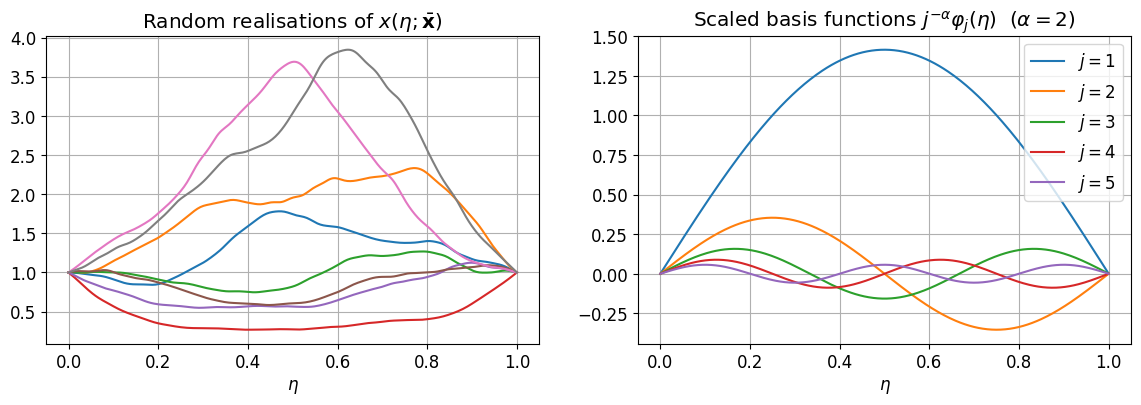

In [3]:
eta = np.linspace(0, 1, 300)

fig, axs = plt.subplots(1, 2, figsize=(14, 4))

axs[0].set_title(r'Random realisations of $x(\eta;\bar{\mathbf{x}})$')
for _ in range(8):
    axs[0].plot(eta, Encoder(parameter=rng.uniform(-1., 1., 50))(eta))
axs[0].set_xlabel(r'$\eta$'); axs[0].grid()

axs[1].set_title(r'Scaled basis functions $j^{-\alpha} \varphi_j(\eta)$  ($\alpha=2$)')
for j in range(1, 6):
    axs[1].plot(eta, j**(-2.) * np.sqrt(2) * np.sin(np.pi * j * eta), label=f'$j={j}$')
axs[1].set_xlabel(r'$\eta$'); axs[1].legend(); axs[1].grid()
plt.show()

## 2. Output Decoder

For the decoder, we choose a data-driven approach based on PCA (Section 3.2), capturing the dominant directions of variation of the solution data.

Starting from $n$ solution samples $(y^{(k)})_{k=1}^n$, PCA computes the empirical mean $\bar{y}$ and the leading singular vectors of the centred data matrix $[y^{(k)} - \bar{y}]_{k=1}^n$. The analysis and synthesis maps of Eq. (3.10) are
$$
  \bar{\mathbf{y}} = \Psi_d^\top(y - \bar{y}),
  \qquad
  y \approx \Psi_d\bar{\mathbf{y}} + \bar{y},
$$
where $\Psi_d \in \mathbb{R}^{N \times d}$ collects the leading $d$ left singular vectors (the PCA modes).

In [4]:
#EXPORT

class Decoder:
    """
    Data-driven output decoder: PCA built from a sample of solution vectors (Section 3.2).
    Implements Eq. (3.10): analysis subtracts the empirical mean, synthesis adds it back.

    Parameters
    ----------
    rank    : int             -- number of PCA modes to retain
    samples : (N, n) ndarray  -- each column is one sample solution
    """

    def __init__(self, *, rank, samples):
        self.mean             = samples.mean(axis=1)              # empirical mean,  shape (N,)
        centered              = samples - self.mean[:, None]      # centred data,    shape (N, n)
        U, S, Vt              = sp.linalg.svd(centered, full_matrices=False)
        self.rank             = rank
        self.projector_c_to_f = U[:, :rank]    # PCA modes,       shape (N, rank)
        self.projector_f_to_c = U[:, :rank].T  # analysis matrix, shape (rank, N)
        self.singular_values  = S[:rank]

    def analyse(self, y):
        """ Analysis: centre and project onto PCA modes.  y: (..., N) -> yb: (..., rank) """
        return (y - self.mean) @ self.projector_f_to_c.T

    def synthesise(self, yb):
        """ Synthesis: reconstruct and add mean.  yb: (..., rank) -> y: (..., N) """
        return yb @ self.projector_c_to_f.T + self.mean

## 3. Dataset

We generate $n$ paired samples $(\bar{\mathbf{x}}^{(k)}, y^{(k)})$ by drawing random encoded parameter vectors, evaluating the corresponding diffusion coefficients, solving the PDE, and fitting the PCA.

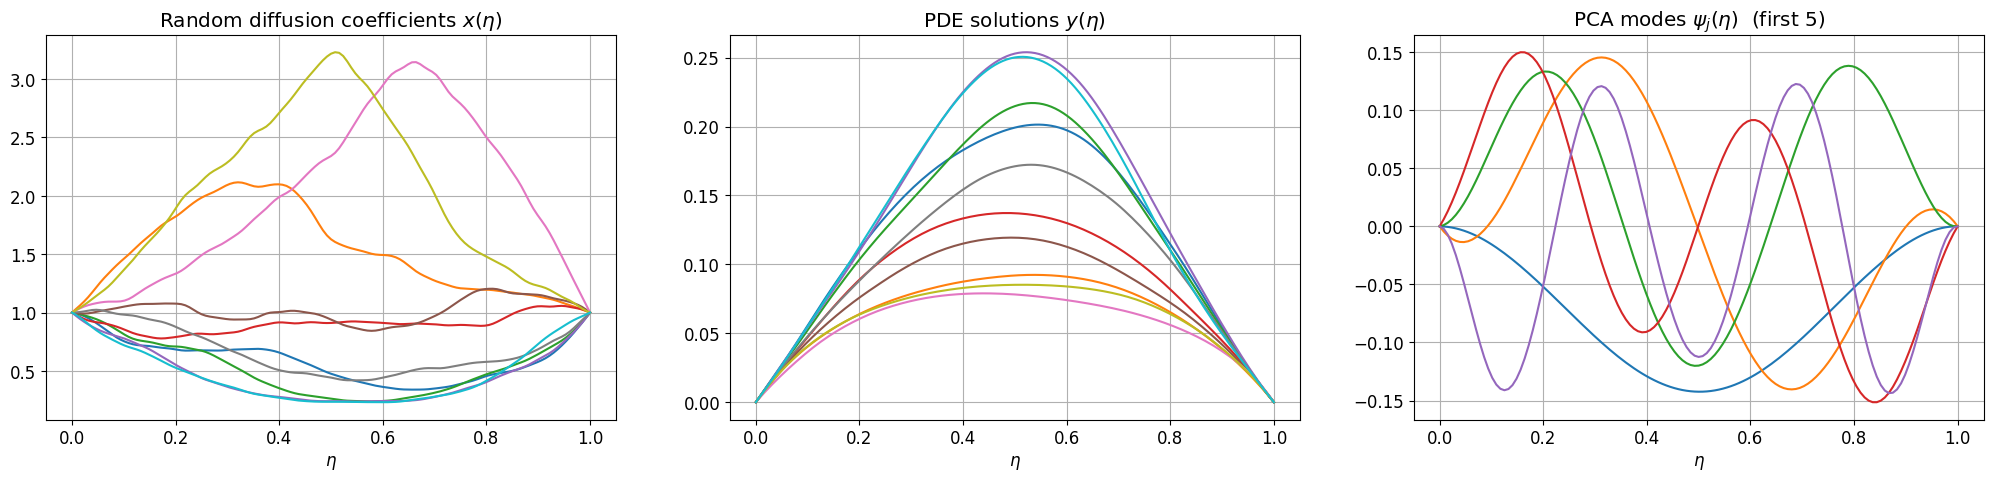

In [5]:
d_in  = 50    # number of sine modes  (input dimension)
d_out = 50    # number of PCA modes   (output dimension)
n     = 1000  # number of samples
grid  = Grid(128)

data = {}

# --- input ---
# sample random encoded parameters xb ~ Uniform[-1, 1]
data['xb'] = rng.uniform(-1., 1., (n, d_in))

# build Encoder objects and evaluate on the grid
x_fields     = [Encoder(parameter=xb) for xb in data['xb']]
data['x']   = np.array([x(grid.nodes_bd) for x in x_fields])

# --- output ---
# solve the PDE for each coefficient field
data['y']   = np.array([Diffusion(coefficient=x)(grid) for x in x_fields])

# fit PCA on the solution data and analyse
decoder     = Decoder(rank=d_out, samples=data['y'].T)
data['yb'] = decoder.analyse(data['y'])

fig, axs = plt.subplots(1, 3, figsize=(25, 5))
axs[0].set_title(r'Random diffusion coefficients $x(\eta)$'); axs[0].plot(grid.nodes_bd, data['x'][:10].T)
axs[1].set_title(r'PDE solutions $y(\eta)$');              axs[1].plot(grid.nodes_bd, data['y'][:10].T)
axs[2].set_title(r'PCA modes $\psi_j(\eta)$  (first 5)');  axs[2].plot(grid.nodes_bd, decoder.projector_c_to_f[:, :5])
for ax in axs: ax.set_xlabel(r'$\eta$'); ax.grid()
plt.show()

## 4. Effect of the Smoothness Parameter

The decay exponent $\alpha$ in $j^{-\alpha}$ controls how quickly the amplitude of higher-frequency sine modes falls off.  A large $\alpha$ suppresses high frequencies, producing smooth realisations of $x(\eta;\bar{\mathbf{x}})$; a small $\alpha$ retains significant high-frequency content, producing rough realisations.

### Diffusion coefficient realisations

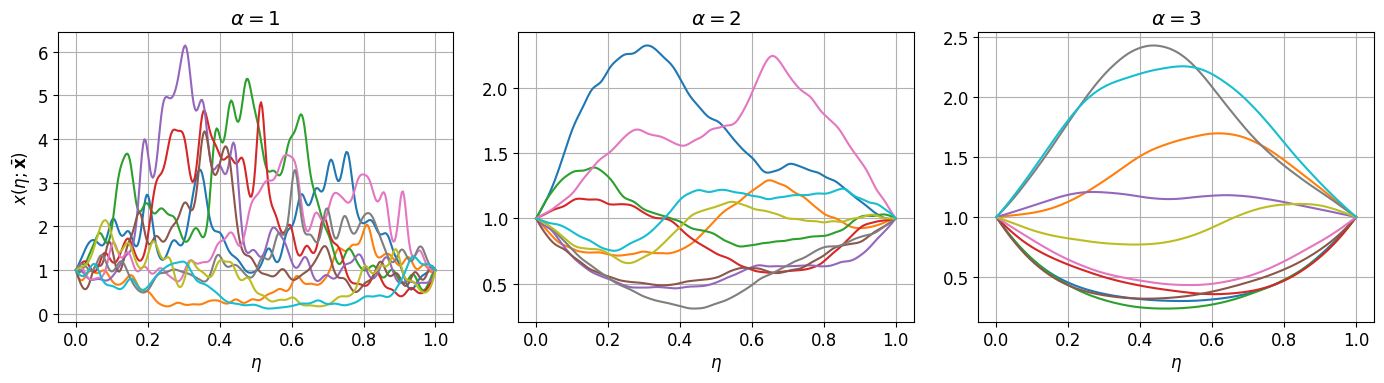

In [6]:
decays = [1, 2, 3]
n_show = 10
rng_show = np.random.default_rng(42)

# draw xb vectors per decay; same params reused for the solution plot below
params = {decay: rng_show.uniform(-1., 1., (n_show, d_in)) for decay in decays}

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=False)
for ax, decay in zip(axs, decays):
    for x in params[decay]:
        ax.plot(eta, Encoder(parameter=x, decay=decay)(eta))
    ax.set_title(rf'$\alpha = {decay}$')
    ax.set_xlabel(r'$\eta$'); ax.grid()
axs[0].set_ylabel(r'$x(\eta;\bar{\mathbf{x}})$')
plt.tight_layout()
plt.show()

### PDE solution realisations

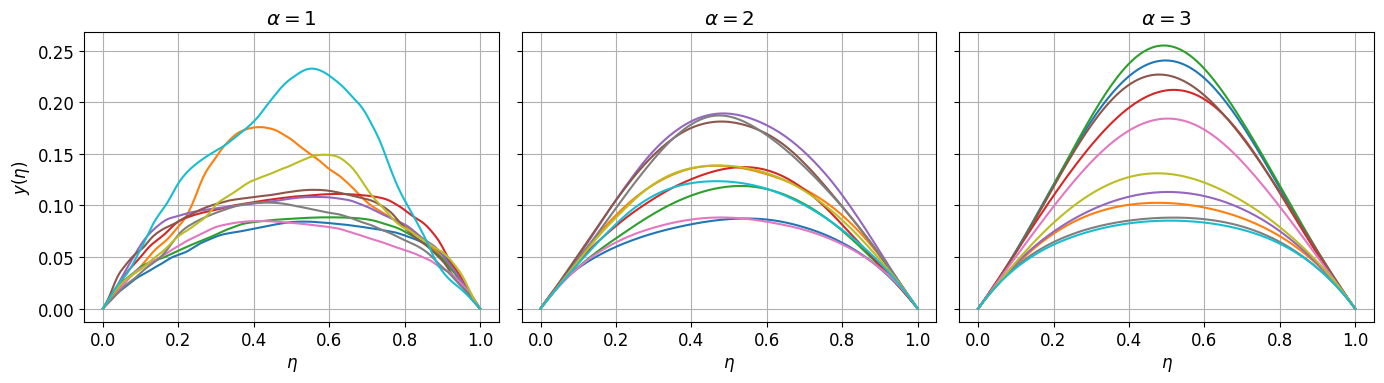

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, decay in zip(axs, decays):
    for x in params[decay]:
        ax.plot(grid.nodes_bd, Diffusion(coefficient=Encoder(parameter=x, decay=decay))(grid))
    ax.set_title(rf'$\alpha = {decay}$')
    ax.set_xlabel(r'$\eta$'); ax.grid()
axs[0].set_ylabel(r'$y(\eta)$')
plt.tight_layout()
plt.show()

### Singular value decay

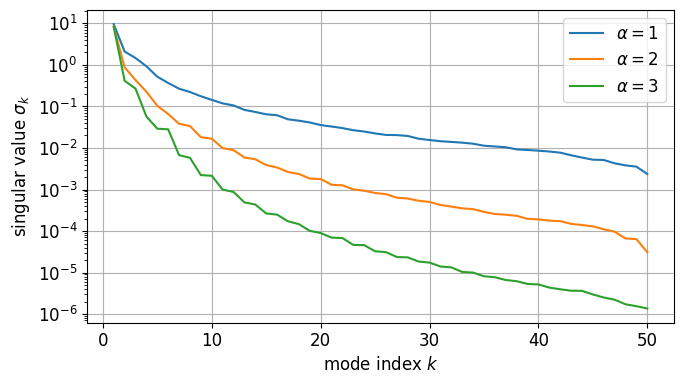

In [8]:
n_pca = 500
rng_pca = np.random.default_rng(1)

fig, ax = plt.subplots(figsize=(7, 4))
for decay in decays:
    x_samp = rng_pca.uniform(-1., 1., (n_pca, d_in))
    y_samp = np.array([Diffusion(coefficient=Encoder(parameter=xb, decay=decay))(grid) for xb in x_samp])
    dec_d  = Decoder(rank=min(y_samp.shape[1] - 1, n_pca - 1), samples=y_samp.T)
    sv_idx = np.arange(1, len(dec_d.singular_values) + 1)
    ax.semilogy(sv_idx[:50], dec_d.singular_values[:50], label=rf'$\alpha = {decay}$')

ax.set_xlabel('mode index $k$'); ax.set_ylabel(r'singular value $\sigma_k$')
ax.legend(); ax.grid(); plt.tight_layout()
plt.show()